# Факторы деградации жилого фонда в РФ: предсказание аварийности многоквартирных домов методами машинного обучения
Исследовательский вопрос: Насколько точно алгоритмы машинного обучения способны предсказывать официальный статус аварийности многоквартирного дома, и каков относительный вклад институциональных (тип управления, регион) и инфраструктурных (возраст, площадь, материал) предикторов в эту вероятность?


## Данные
Датасет взят с сайта [Если быть точным](https://tochno.st/datasets/gisgkh).

**Что в данных**: износ и аварийность жилых домов.

Данные об исправности и аварийности многоквартирных жилых домов (МКД) России, внесённых в Государственную информационную систему жилищно-коммунального хозяйства (ГИС ЖКХ). Сведения актуальны по состоянию на ноябрь 2025 года. Объём: ~956 тыс. домов, 33 признака.

### Целевая переменная
Исходный атрибут **condition** (состояние здания) распределён следующим образом:

| Состояние | Число домов | Доля |
|---|---|---|
| Исправный | 857 093 | 90,7% |
| Аварийный | 79 031 | 8,4% |
| Ветхий | 9 238 | 1,0% |

Дома без указанного состояния (`NaN`, «Не выбран») из выборки исключаются.

Моделирование проводится в два этапа:

1. **Основная задача — проблемный фонд против исправного.** Бинарная переменная **target**: «Аварийный» и «Ветхий» — класс 1 (~9%), «Исправный» — класс 0. Эта модель отвечает на исследовательский вопрос: насколько предсказуем статус проблемного дома и каков вклад институциональных и инфраструктурных факторов.
2. **Вспомогательная задача — ветхий против аварийного.** Модель обучается только на проблемном фонде (~88 тыс. домов): «Ветхий» — класс 1 (~10%), «Аварийный» — класс 0.

Разделение на два этапа обусловлено тем, что по физическим характеристикам ветхие и аварийные дома почти не различаются: медианный год ввода 1957 и 1959, медианный износ 62% и 65%; ветхие дома лишь меньше (~193 м² и 4 квартиры против ~358 м² и 8 квартир). При этом это разные правовые статусы: ветхий дом требует капитального ремонта, аварийный подлежит сносу или реконструкции и расселению. В единой трёхклассовой модели редкий (1%) и плохо отделимый класс «Ветхий» размывал бы метрики и важность признаков, тогда как двухэтапная схема позволяет интерпретировать каждое решение отдельно.

Вспомогательная модель ценна прежде всего важностью признаков. Если различие между ветхим и аварийным статусом объясняется в основном регионом и муниципалитетом, а не возрастом и материалом стен, это свидетельствует о том, что статус в значительной мере определяется административной практикой. На это указывает и концентрация ветхого фонда: 42% таких домов сосредоточены в пяти регионах (Архангельская, Самарская, Тульская, Нижегородская области, ХМАО).

### Используемые признаки
1. Инфраструктурные и архитектурные:
- **building_year** (год постройки; при пропуске — **comissioning_year**, год ввода в эксплуатацию) — базовая метрика физического старения. Значения-диапазоны вида «2001, 2002» приводятся к первому году.
- **total_area**, **residental_premises_area** (общая и жилая площадь), **flats** (число квартир) — масштаб объекта. Аварийный фонд — это преимущественно малые дома: медианная площадь ~345 м² и 7 квартир против ~1 780 м² и 27 квартир у исправных. Явно ошибочные значения площади (0, 1 м²) считаются пропусками.
- **internal_walls_type** (материал стен) и **plan_series** (серия проекта) — конструктивные характеристики. Исходные значения сильно «загрязнены» (более 2 тыс. и 57 тыс. уникальных вариантов написания), поэтому они сведены к укрупнённым группам (кирпич, панель, блоки, дерево и т.п.).
- **is_reconstructed** — бинарный признак, построенный по наличию записи в поле reconstruction_year (факт капитальных вложений в здание).

2. Институциональные и пространственные:
- **region_name** (регион) и **municipality_oktmo** (код муниципалитета по ОКТМО) — отражают бюджетную обеспеченность и пространственное неравенство.
- **house_management_type** (способ управления: УО, ТСЖ, ЖК, непосредственное управление и др.) — отражает способность собственников решать проблему коллективного действия. Доля аварийных и ветхих домов: ТСЖ — 0,8%, УО — 6%, непосредственное управление — 16%.
- **municipal_property** (наличие муниципальной собственности в доме) — индикатор участия публичного собственника: при значении «да» доля проблемного фонда достигает 45%.

### Исключённые признаки
- **Утечка целевой переменной** — признаки, которые являются следствием аварийности, а не её причиной: **deterioration** (процент износа — по нормативам статус «ветхий» определяется именно через износ), **deterioration_estimation_date**, **life_cycle_stage** (стадии «Расселён», «Снос», «Выведен из эксплуатации» наступают после признания дома аварийным), **management_organization_name/link** (у расселённых домов управляющая организация отсутствует).
- **Идентификаторы**: full_address, fias_id, cadastral_number, gisgkh_guid, postal_code.
- **Дублирующие**: region_oktmo, region_okato, municipality_okato, timezone.
- **Неинформативные**: house_type (99,9% — «Многоквартирный»), regional_property (значение «да» лишь у 55 домов), energy_efficency_class (86% пропусков).
- **Технические**: latitude, longitude — дают завышенную оценку качества из-за пространственной автокорреляции соседних домов; qc_geo — атрибут реестра, а не свойство дома.  

In [273]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [274]:
df = pd.read_csv("data_gisgkh_157_v20260917.csv", delimiter=";", encoding="utf-8")
df.head()

,full_address,region_name,region_oktmo,region_okato,municipality_oktmo,municipality_okato,postal_code,latitude,longitude,qc_geo,...,deterioration_estimation_date,condition,internal_walls_type,reconstruction_year,energy_efficency_class,house_management_type,management_organization_name,management_organization_link,regional_property,municipal_property
0,"обл Оренбургская, г Орск, ул Докучаева, д. 23",Оренбургская область,53000000,53000000,5.372300e+10,5.342300e+10,462401.0,51.229249,58.529401,Точные координаты,...,01.01.2017,Исправный,Стены из слоистых железобетонных панелей,NaN,NaN,УО,"ООО ""УК ""ДЕЙСТВИЕ""",https://dom.gosuslugi.ru/#!/organizationView/8...,NaN,NaN
1,"Респ Башкортостан, г Нефтекамск, ул Карцева, д...",Республика Башкортостан,80000000,80000000,8.072700e+10,8.042700e+10,452687.0,56.077100,54.225304,Точные координаты,...,26.03.2025,Исправный,Стены кирпичные,NaN,NaN,УО,"ООО ""Мегаполис""",https://dom.gosuslugi.ru/#!/organizationView/3...,False,False
2,"Респ Башкортостан, г Нефтекамск, ул Карцева, д...",Республика Башкортостан,80000000,80000000,8.072700e+10,8.042700e+10,452687.0,56.077386,54.224518,Точные координаты,...,26.03.2025,Исправный,Стены кирпичные,NaN,NaN,УО,"ООО ""Мегаполис""",https://dom.gosuslugi.ru/#!/organizationView/3...,False,False
3,"Респ Башкортостан, г Нефтекамск, ул Карцева, д...",Республика Башкортостан,80000000,80000000,8.072700e+10,8.042700e+10,452687.0,56.077664,54.223853,Точные координаты,...,03.04.2025,Исправный,Стены кирпичные,NaN,С (Нормальный),УО,"ООО ""УК ""СВОЙ ДОМ""",https://dom.gosuslugi.ru/#!/organizationView/9...,False,False
4,"Респ Башкортостан, г Нефтекамск, ул Карцева, д...",Республика Башкортостан,80000000,80000000,8.072700e+10,8.042700e+10,452687.0,56.077926,54.223225,Точные координаты,...,26.03.2025,Исправный,Стены кирпичные,NaN,С (Нормальный),УО,"ООО ""УК ""СВОЙ ДОМ""",https://dom.gosuslugi.ru/#!/organizationView/9...,False,False


In [275]:
TARGET = "condition"
RANDOM_STATE = 42

COLORS = {
    "accent": "#4654f5",
    "header": "#959ef2",
    "background": "#EEEEEE",
    "text": "#000000",
    "index_background": "#A0CCFF"
}

PLOT_COLOR = COLORS["accent"]

def style_table(df, caption, colors=COLORS, hide_index=True):
    styler = df.style.set_caption(caption)
    if hide_index:
        styler = styler.hide(axis="index")
    return styler.set_table_styles([
        {"selector": "caption", "props": f"font-size:16px; font-weight:bold; color:{colors['text']};"},
        {"selector": "th", "props": f"background-color:{colors['header']}; color:{colors['text']}; border:1px solid #ccc;"},
        {"selector": "td", "props": f"background-color:{colors['background']}; color:{colors['text']}; border:1px solid #ccc;"},
        {"selector": ".row_heading", "props": f"background-color:{colors['index_background']}; color:{colors['text']}; font-weight:bold; border:1px solid #ccc;"},
    ])

In [276]:
info_df = pd.DataFrame(
    {
        'Column': df.columns,
        'Non-Null': df.notnull().sum().values,
        'Dtype': df.dtypes.values,
    }
)
style_table(info_df, "Dataframe info")

Column,Non-Null,Dtype
full_address,956147,str
region_name,956147,str
region_oktmo,956147,int64
region_okato,956147,int64
municipality_oktmo,938351,float64
municipality_okato,938351,float64
postal_code,955464,float64
latitude,937904,float64
longitude,937904,float64
qc_geo,938351,str


In [277]:
# Data overview

overview = pd.DataFrame({
    "Metric": ["Shape", "Number of features", "Missing Values", "Duplicate Rows"],
    "Value": [df.shape, df.drop(TARGET, axis=1).columns.size, df.isnull().sum().sum(), df.duplicated().sum()]
})
style_table(overview, "Dataset Overview")

Metric,Value
Shape,"(956147, 33)"
Number of features,32
Missing Values,4725859
Duplicate Rows,0


In [278]:
# Target distribution

target_distribution = df[TARGET].value_counts()
target_distribution
target_distribution_df = pd.DataFrame({
    "Condition": target_distribution.index,
    "Count": target_distribution.values,
    "Percentage": (target_distribution.values / target_distribution.sum()) * 100  
})
style_table(target_distribution_df, "Target distribution").format({
    "Count": "{:,.0f}",
    "Percentage": "{:.2f}%"
})

Condition,Count,Percentage
Исправный,"857,093",90.66%
Аварийный,"79,031",8.36%
Ветхий,"9,238",0.98%
Не выбран,29,0.00%


In [279]:
# Missing values

missing_values = df.isna().sum()
missing_values_df = pd.DataFrame({
    "Feature": missing_values.index,
    "Count": missing_values.values,
    "Percentage": (missing_values.values / len(df)) * 100
})

style_table(missing_values_df, "Missing values").format({
    "Count": "{:,.0f}",
    "Percentage": "{:.2f}%"
})

Feature,Count,Percentage
full_address,0,0.00%
region_name,0,0.00%
region_oktmo,0,0.00%
region_okato,0,0.00%
municipality_oktmo,"17,796",1.86%
municipality_okato,"17,796",1.86%
postal_code,683,0.07%
latitude,"18,243",1.91%
longitude,"18,243",1.91%
qc_geo,"17,796",1.86%


In [280]:
style_table(df.describe().T, "Numeric describe", hide_index=False).format("{:,.2f}")

,count,mean,std,min,25%,50%,75%,max
region_oktmo,"956,147.00","46,558,378.58","26,728,169.21","1,000,000.00","25,000,000.00","46,000,000.00","68,000,000.00","99,000,000.00"
region_okato,"956,147.00","46,526,660.48","26,726,793.74","1,000,000.00","25,000,000.00","46,000,000.00","68,000,000.00","99,000,000.00"
municipality_oktmo,"938,351.00","44,205,523,617.96","29,163,809,058.04","2,000,000.00","19,536,000,159.00","46,515,000,573.00","68,715,000,001.00","99,701,000,001.00"
municipality_okato,"938,351.00","46,938,544,368.18","26,666,535,657.86","1,201,802,001.00","25,224,551,000.00","46,410,000,000.00","68,415,000,000.00","99,401,000,000.00"
postal_code,"955,464.00","403,255.51","196,663.54",0.00,"188,561.00","400,138.00","620,135.00","694,923.00"
latitude,"937,904.00",54.84,5.05,41.46,52.63,55.43,57.41,73.51
longitude,"937,904.00",55.17,28.87,-179.48,37.70,44.02,60.62,179.26
flats,"938,347.00",51.55,82.18,0.00,8.00,21.00,70.00,"5,545.00"
comissioning_year,"934,127.00","1,974.87",74.71,0.00,"1,961.00","1,975.00","1,989.00","36,892.00"
total_area,"955,943.00","3,250.08","6,238.96",-90.80,426.20,"1,330.30","3,860.70","826,976.00"


In [281]:
style_table(df.describe(include='str').T, "String describe", hide_index=False)

,count,unique,top,freq
full_address,956147,956006,"край Алтайский, р-н Краснощёковский, с Краснощёково, ул Ленина, д. 144",2
region_name,956147,85,Московская область,52104
qc_geo,938351,6,Точные координаты,726044
timezone,938351,11,UTC+3,550028
fias_id,956147,956021,fca0a054-4f63-4dbf-b985-c87c47c5b4f9,2
cadastral_number,934804,933401,отсутствует,16
gisgkh_guid,956147,956147,762cf039-7a6f-4219-ba47-a7d895462e84,1
house_type,956147,2,Многоквартирный,955472
life_cycle_stage,923199,7,Эксплуатация,904811
building_year,890127,1175,1960,21957


## Разведочный анализ данных (EDA)
*Проблема пропусков*: В исходных данных зафиксировано значительное число пропусков в категориальных переменных (например, plan_series, municipality_name). В логике нашего исследования отсутствие записи в государственном реестре само по себе является информативным сигналом (дефицит административного контроля). Поэтому пропуски в категориальных номинальных шкалах заполнены значением «Не указано». Пропуски в непрерывных числовых переменных (площадь) заполнены медианными значениями.

### Очистка данных

In [282]:
# Очистка целевой переменной

df = df[df["condition"] != "Не выбран"]

In [283]:
# Преобразование comissioning_year

df["comissioning_year"] = df["comissioning_year"].astype("Int64")

mask = (df['comissioning_year'] > 1800) & (df['comissioning_year'] <= 2026)
df = df[mask]

style_table(pd.DataFrame({"Count": [len(mask) - mask.sum()], "Percentage": [1 - mask.sum() / len(mask)]}), "Deleted comissioning_year rows").format({
    "Count": "{:,.0f}",
    "Percentage": "{:.2f}%"
})

Count,Percentage
"22,848",0.02%


In [284]:
# Преобразование building_year

df["building_year"] = df["building_year"].fillna(df["comissioning_year"])
df["building_year"] = df["building_year"].str.split(",").str[0].astype("Int64")

mask = (df['building_year'] > 1800) & (df['building_year'] <= 2026)
df = df[mask]

style_table(pd.DataFrame({"Count": [len(mask) - mask.sum()], "Percentage": [1 - mask.sum() / len(mask)]}), "Deleted building_year rows").format({
    "Count": "{:,.0f}",
    "Percentage": "{:.2f}%"
})

Count,Percentage
"51,467",0.06%


In [285]:
# Преобразование признаков площади

mask = (df["total_area"] > 1) & (df["residental_premises_area"] > 1)

df = df[mask]
df["residental_ratio"] = df["residental_premises_area"] / df["total_area"]
df["flats_area_ratio"] = df["flats"] / df["total_area"]

style_table(pd.DataFrame({"Count": [len(mask) - mask.sum()], 
                          "Percentage": [1 - mask.sum() / len(mask)]}), 
                          "Deleted area rows").format({
                              "Count": "{:,.0f}",
                              "Percentage": "{:.2f}%"
                          })

Count,Percentage
"64,813",0.07%


In [286]:
# Топ 95% категорий признака internal_walls_type

vc = df["internal_walls_type"].str.lower().str.strip().value_counts()
cum = vc.cumsum() / vc.sum()
d = {q: (cum < q).sum() + 1 for q in (.8, .9, .95, .99)}

top = d.get(0.95)
materials = vc.head(top)
materials_df = pd.DataFrame({"Material": materials.index, 
                             "Count": materials.values,
                             "Percentage": materials.values / len(df["internal_walls_type"]) * 100
})
style_table(materials_df,"Top 95% walls type rows").format({
    "Count": "{:,.0f}",
    "Percentage": "{:.2f}%"
})

Material,Count,Percentage
стены кирпичные,"333,092",40.77%
стены из слоистых железобетонных панелей,"49,044",6.00%
стены из несущих панелей,"40,730",4.99%
стены деревянные,"35,281",4.32%
стены рубленные из бревен и брусчатые,"27,059",3.31%
стены из ж/б панелей,"25,254",3.09%
стены из крупноразмерных блоков и однослойных несущих панелей,"21,460",2.63%
"стены деревянные, сборно-щитовые","17,091",2.09%
стены из шлакоблоков,"16,512",2.02%
панельные,"15,858",1.94%


In [287]:
import re

WALL_RULES = [
    ("Дерево",    r"дерев|брус|бревен|бревн|рублен|сруб|щит|каркасн|засыпн|арболит|арбоблок|фибролит"),
    ("Монолит",   r"монолит"),
    ("Кирпич",    r"кирпич"),
    ("Шлакоблок", r"шлак"),
    ("Блоки",     r"блок|газобет|пенобет|газосилик|ячеист|силикальцит|камн|поротерм"),
    ("Панель",    r"панел|плит|железобет|ж/б"),
    ("Гипсолит",  r"гипс"),
]

def map_wall_part(part):
    for group, pattern in WALL_RULES:
        if re.search(pattern, part):
            return group
    return None

def map_walls(value):
    if pd.isna(value) or not str(value).strip():
        return "Не указано"
    text = str(value).lower().replace("\u00ad", "")
    parts = [p.strip() for p in re.split(r"[,;/+]", text) if p.strip()]
    groups = {g for g in map(map_wall_part, parts) if g}
    if not groups:
        return "Прочее"
    return groups.pop() if len(groups) == 1 else "Смешанные"

uniq = df["internal_walls_type"].dropna().unique()
walls_mapping = {v: map_walls(v) for v in uniq}
df["walls_group"] = df["internal_walls_type"].map(walls_mapping).fillna("Не указано")

In [288]:
walls_group = df["walls_group"].value_counts(dropna=False)

walls_group_df = pd.DataFrame({
    "Walls type": walls_group.index,
    "Count": walls_group.values,
    "Percentage": (walls_group.values / len(df["walls_group"])) * 100
})

style_table(walls_group_df, "Walls type").format({
    "Count": "{:,.0f}",
    "Percentage": "{:.2f}%"
})

Walls type,Count,Percentage
Кирпич,"334,478",40.94%
Панель,"167,563",20.51%
Дерево,"116,409",14.25%
Не указано,"75,184",9.20%
Блоки,"49,654",6.08%
Смешанные,"27,181",3.33%
Шлакоблок,"18,129",2.22%
Монолит,"16,637",2.04%
Гипсолит,"11,640",1.42%
Прочее,115,0.01%


In [289]:
# Топ 95% категорий признака plan_series

vc = df["plan_series"].str.lower().str.strip().value_counts()
cum = vc.cumsum() / vc.sum()
d = {q: (cum < q).sum() + 1 for q in (.8, .9, .95, .99)}

print(f"Топ 95% категорий признака plan_series {d.get(0.95)}")

Топ 95% категорий признака plan_series 17234


In [290]:
PLAN_KIND_RULES = [
    ("Индивидуальный", r"не ?типов|нетипов|не ?серийн|инд|автор|^ип$"),
    ("Серийный",       r"(?<!\d)(?:[iп1]\s*-?\s*)?\d{2,3}(?!\d)"),
    ("Типовой",        r"типов|повторн|экспер"),
]

def map_plan_kind(raw):
    if pd.isna(raw):
        return "Не указано"
    parts = [p.strip() for p in re.split(r"[,;:/]", str(raw).lower()) if p.strip()]
    kinds = set()
    for part in parts:
        for group, rule in PLAN_KIND_RULES:
            if re.search(rule, part):
                kinds.add(group)
                break
    for group in ("Серийный", "Индивидуальный", "Типовой"):   # приоритет при конфликте
        if group in kinds:
            return group
    return "Не указано"

uniq = df["plan_series"].dropna().unique()
plan_kind_mapping = {v: map_plan_kind(v) for v in uniq}
df["plan_kind"] = df["plan_series"].map(plan_kind_mapping).fillna("Не указано")

In [291]:
plan_kind = df["plan_kind"].value_counts(dropna=False)

plan_kind_df = pd.DataFrame({
    "Plan kind": plan_kind.index,
    "Count": plan_kind.values,
    "Percentage": (plan_kind.values / len(df["plan_kind"])) * 100
})

style_table(plan_kind_df, "Plan kind").format({
    "Count": "{:,.0f}",
    "Percentage": "{:.2f}%"
})

Plan kind,Count,Percentage
Не указано,"526,811",64.48%
Серийный,"172,098",21.06%
Индивидуальный,"87,033",10.65%
Типовой,"31,048",3.80%


In [292]:
# Преобразование municipality_oktmo в строковое значение

oktmo = df["municipality_oktmo"].astype("Int64").astype("string")
postal_to_oktmo = (
    pd.DataFrame({"postal_code": df["postal_code"], "oktmo": oktmo})
    .dropna()
    .value_counts()
    .reset_index()
    .drop_duplicates("postal_code", keep="first")
    .set_index("postal_code")["oktmo"]
)

df["municipality_oktmo"] = oktmo.fillna(df["postal_code"].map(postal_to_oktmo)).fillna("Не указано")

In [293]:
# Преобразование flats в целочисленное значение

df["flats"] = df["flats"].astype("Int64")

In [294]:
house_type = df["house_type"].value_counts(dropna=False) 

house_type_df = pd.DataFrame({
    "Type": house_type.index,
    "Count": house_type.values,
    "Percentage": house_type.values / len(df["house_type"]) * 100
})

style_table(house_type_df, "House type type").format({
    "Count": "{:,.0f}",
    "Percentage": "{:.2f}%"
})

Type,Count,Percentage
Многоквартирный,"816,797",99.98%
Жилой,193,0.02%


Признак house_type можно исключить как неинформативный

In [295]:
regional_property = df["regional_property"].value_counts(dropna=False)

regional_property_df = pd.DataFrame({
    "Type": regional_property.index,
    "Count": regional_property.values,
    "Percentage": regional_property.values / len(df["regional_property"]) * 100
})

style_table(regional_property_df, "Regional property").format({
    "Count": "{:,.0f}",
    "Percentage": "{:.2f}%"
})

Type,Count,Percentage
nan,"450,639",55.16%
False,"366,303",44.84%
True,48,0.01%


Признак regional_property можно исключить как неинформативный (только 0.01% домов в датасете являются региональной собственностью)

In [296]:
energy_efficency_class = df["energy_efficency_class"].value_counts(dropna=False)

energy_efficency_class_df = pd.DataFrame({
    "Type": energy_efficency_class.index,
    "Count": energy_efficency_class.values,
    "Percentage": energy_efficency_class.values / len(df["energy_efficency_class"]) * 100
})

style_table(energy_efficency_class_df, "Energy efficency class").format({
    "Count": "{:,.0f}",
    "Percentage": "{:.2f}%"
})

Type,Count,Percentage
nan,"693,412",84.87%
Нет,"43,803",5.36%
С (Нормальный),"21,992",2.69%
D (Пониженный),"14,151",1.73%
E (Низкий),"12,600",1.54%
В (Высокий),"6,042",0.74%
Е (Пониженный - приказ Минстроя №399/пр),"4,954",0.61%
В+ (Высокий),"4,610",0.56%
D (Нормальный - приказ Минстроя №399/пр),"4,407",0.54%
А (Очень высокий),"2,584",0.32%


Признак energy_efficency_class можно исключить как неинформативный (84.87% строк не заполнены)

In [297]:
df["house_management_type"] = df["house_management_type"].fillna("Не указано")

In [298]:
# Виды управления многоквартирными домами

managment_type = df["house_management_type"].value_counts(dropna=False)
managment_type_df = pd.DataFrame({
    "Type": managment_type.index,
    "Count": managment_type.values,
    "Percentage": managment_type.values / len(df["house_management_type"]) * 100
})

style_table(managment_type_df, "House managment type").format({
    "Count": "{:,.0f}",
    "Percentage": "{:.2f}%"
})

Type,Count,Percentage
УО,"589,850",72.20%
Непосредственное управление,"167,097",20.45%
ТСЖ,"35,508",4.35%
Не выбран,"12,672",1.55%
ЖК,"7,635",0.93%
Не указано,"3,504",0.43%
"Выбран, но не реализован",488,0.06%
Иной кооператив,236,0.03%


In [299]:
# Признак is_reconstrucsted

df['is_reconstructed'] = df['reconstruction_year'].notna().astype(int)

In [300]:
is_reconstructed = df["is_reconstructed"].value_counts(dropna=False)

is_reconstructed_df = pd.DataFrame({
    "Type": is_reconstructed.index.astype("bool"),
    "Count": is_reconstructed.values,
    "Percentage": is_reconstructed.values / len(df["is_reconstructed"]) * 100
})

style_table(is_reconstructed_df, "Is reconstructed").format({
    "Count": "{:,.0f}",
    "Percentage": "{:.2f}%"
})

Type,Count,Percentage
False,"714,430",87.45%
True,"102,560",12.55%


In [301]:
municipal_property = df["municipal_property"].value_counts(dropna=False)

municipal_property_df = pd.DataFrame({
    "Type": municipal_property.index,
    "Count": municipal_property.values,
    "Percentage": municipal_property.values / len(df["municipal_property"]) * 100
})

style_table(municipal_property_df, "Municipal property").format({
    "Count": "{:,.0f}",
    "Percentage": "{:.2f}%"
})

Type,Count,Percentage
False,"444,445",54.40%
nan,"370,797",45.39%
True,"1,748",0.21%


### Распределение признаков

In [302]:
TARGET = "condition"

df[TARGET] = df[TARGET].map(lambda x: 1 if x in ['Аварийный', 'Ветхий'] else 0)

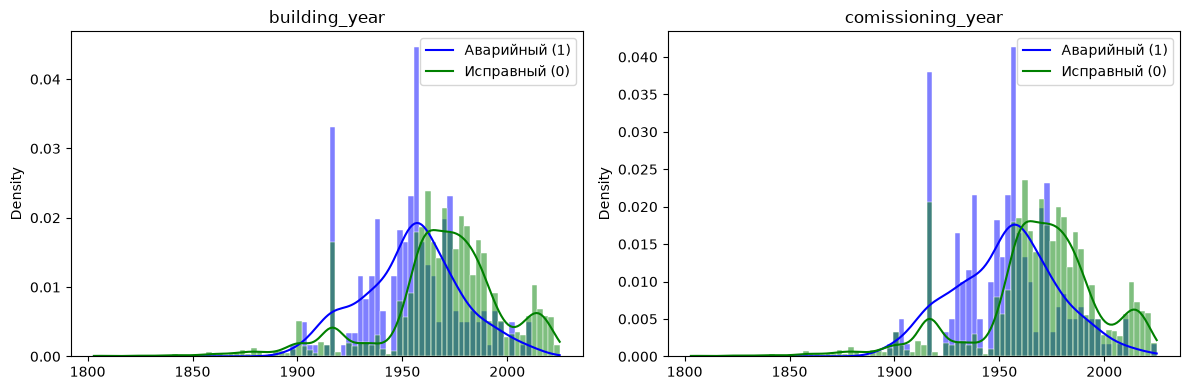

In [303]:
# Распределение по году постройки и ввода в эксплуатацию

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes.flat, ["building_year", "comissioning_year"]):
    sns.histplot(
        data=df.dropna(),
        x=col,
        hue=TARGET,
        edgecolor = "white",
        color = PLOT_COLOR,
        stat="density",
        kde=True,
        common_norm=False,
        palette={0:"g", 1:"b"},
        ax=ax
    )
    ax.set_title(col, color=COLORS["text"])
    ax.legend(["Аварийный (1)", "Исправный (0)"])
    ax.set_xlabel("")
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

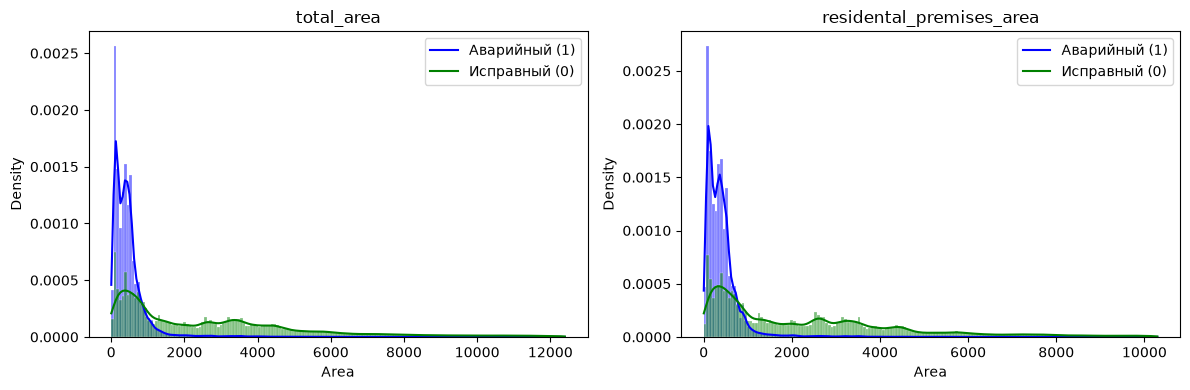

In [304]:
# Распределение по площадям: общая и жилых помещений

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes.flat, ["total_area", "residental_premises_area"]):
    q = df[col].quantile(0.95)
    mask = df[col] <= q
    sns.histplot(
        data=df[mask],
        x=col,
        hue=TARGET,
        edgecolor = "white",
        color = PLOT_COLOR,
        stat="density",
        common_norm=False,
        kde=True,
        palette={0:"g", 1:"b"},
        ax=ax
    )
    ax.set_title(col, color=COLORS["text"])
    ax.legend(["Аварийный (1)", "Исправный (0)"])
    ax.set_xlabel("Area")
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

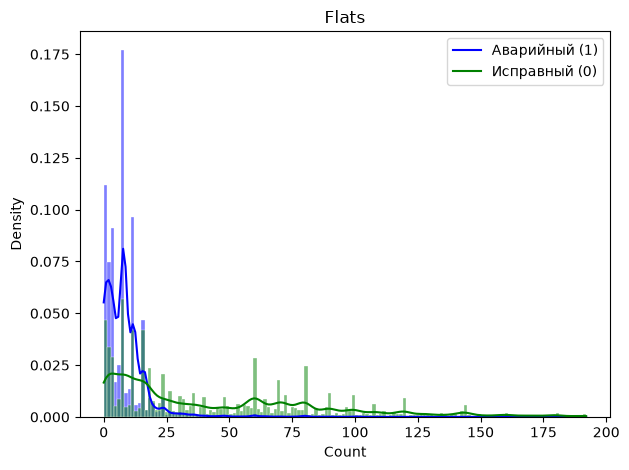

In [305]:
# Распределение количества квартир в домах

q = df["flats"].quantile(0.95)
mask = df["flats"] <= q
sns.histplot(
    data=df[mask],
    x="flats",
    hue=TARGET,
    edgecolor = "white",
    color = PLOT_COLOR,
    stat="density",
    kde=True,
    common_norm=False,
    palette={0:"g", 1:"b"},
)
plt.legend(["Аварийный (1)", "Исправный (0)"])
plt.title("Flats", color=COLORS["text"])
plt.xlabel("Count")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

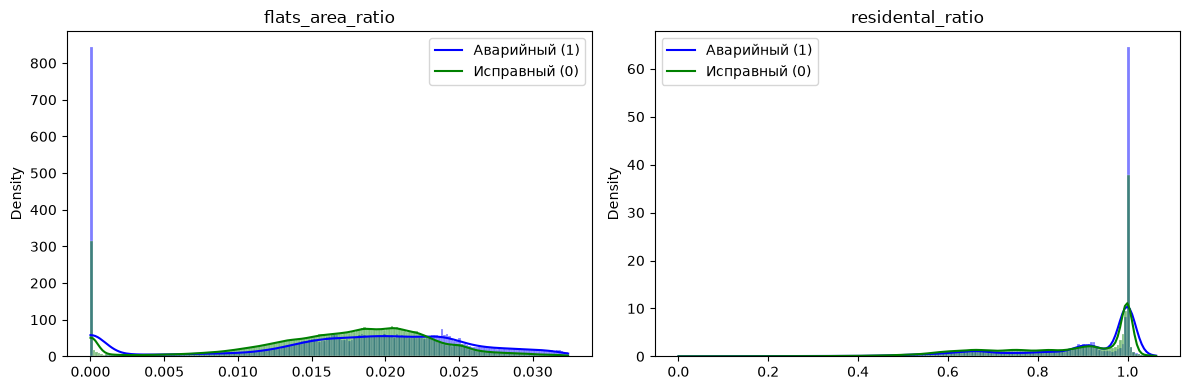

In [306]:
# Распределение по году постройки и ввода в эксплуатацию

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes.flat, ["flats_area_ratio", "residental_ratio"]):
    q = df[col].quantile(0.95)
    mask = df[col] <= q
    sns.histplot(
        data=df[mask],
        x=col,
        hue=TARGET,
        edgecolor = "white",
        color = PLOT_COLOR,
        stat="density",
        kde=True,
        common_norm=False,
        palette={0:"g", 1:"b"},
        ax=ax
    )
    ax.legend(["Аварийный (1)", "Исправный (0)"])
    ax.set_title(col, color=COLORS["text"])
    ax.set_xlabel("")
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

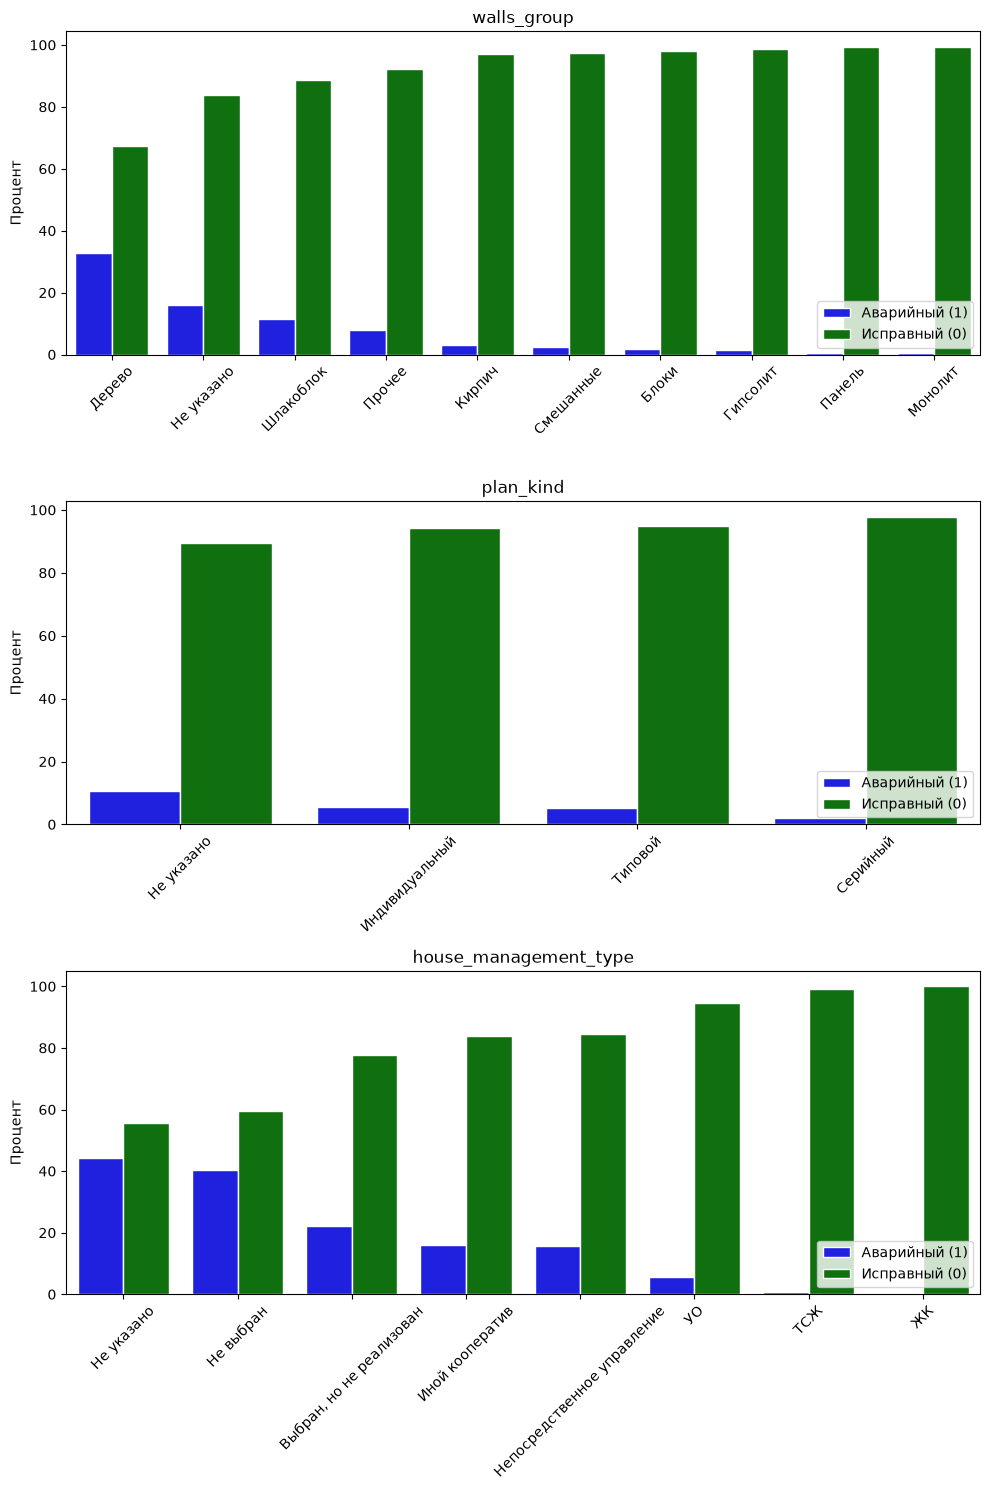

In [307]:
# Распределение категориальных переменных

fig, axes = plt.subplots(3, 1, figsize=(10,15))
for ax, col in zip(axes.flat, [
    "walls_group", 
    "plan_kind", 
    "house_management_type"
]):
    temp = df.groupby([col, TARGET])[TARGET].count().reset_index(name="count")
    temp["percentage"] = temp["count"] / temp.groupby(col)["count"].transform("sum") * 100

    order = (
        temp[temp[TARGET] == 1]
        .sort_values("percentage", ascending=False)[col]
        .tolist()
    )

    sns.barplot(
        data=temp,
        x=col,
        y="percentage",
        hue=TARGET,
        edgecolor="white",
        palette={0: "g", 1: "b"},
        hue_order=[1, 0],
        ax=ax,
        order=order,
        legend=True
    )
    
    handles, _ = ax.get_legend_handles_labels()
    l = ax.get_xticklabels()

    ax.legend(
        handles=handles, 
        labels=["Аварийный (1)", "Исправный (0)"],
        loc="lower right"
    )
    ax.set_title(col, color=COLORS["text"])
    for item in l:
        item.set_rotation(45)
    ax.set_xlabel("")
    ax.set_ylabel("Процент")

plt.tight_layout()
plt.show()

### Распределение целевой переменной по признакам

Text(0, 0.5, 'Количество домов')

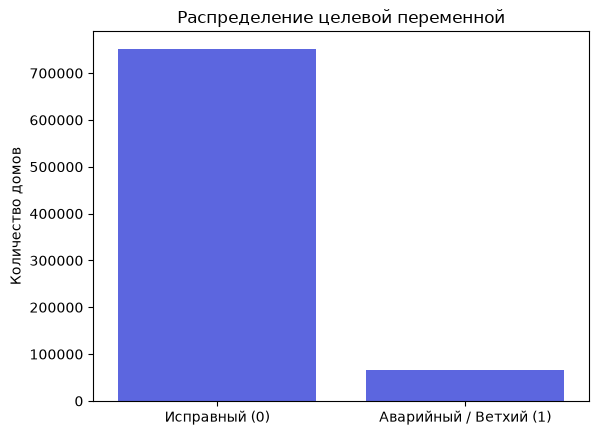

In [308]:
# Распределение целевой переменой

sns.countplot(
    data=df,
    x=TARGET,
    color=PLOT_COLOR
)
plt.title("Распределение целевой переменной")
plt.xticks(ticks=[0,1], labels=["Исправный (0)", "Аварийный / Ветхий (1)"])
plt.xlabel("")
plt.ylabel("Количество домов")

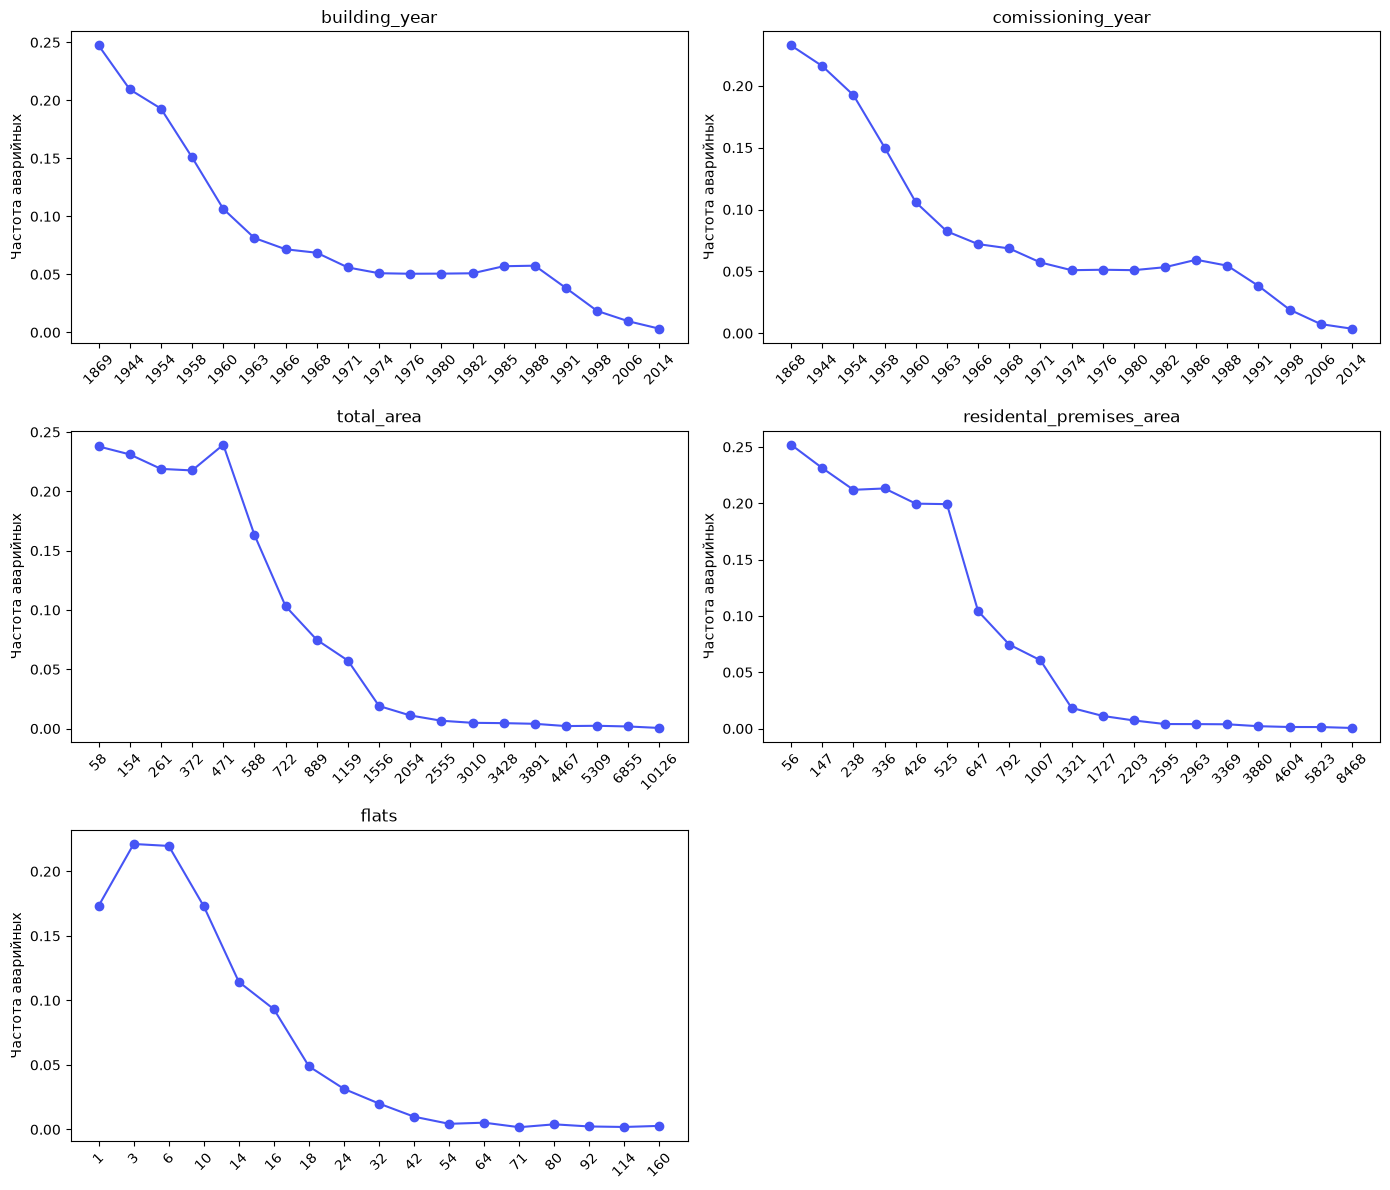

In [309]:
quantiles = np.linspace(0, 1, 20, endpoint=False)

feats = [
    "building_year", 
    "comissioning_year", 
    "total_area", 
    "residental_premises_area", 
    "flats"
]

fig, axes = plt.subplots(3, 2, figsize=(14,12))
for ax, col in zip(axes.flat, feats):
    bins = pd.qcut(df[col], q=quantiles, duplicates="drop")
    temp = df.groupby(bins)[TARGET].mean()
    ax.plot(
        temp.values,
        marker='o',
        color=PLOT_COLOR
    )
    # ax.set_ylim(0,1)
    ax.set_xticks(ticks=range(len(temp)), labels=[f"{b.mid:.0f}" for b in temp.index], rotation=45)
    ax.set_title(col, color=COLORS["text"])
    ax.set_ylabel("Частота аварийных")

for ax in axes.flat[len(feats):]:
    ax.remove()

plt.tight_layout()
plt.show()

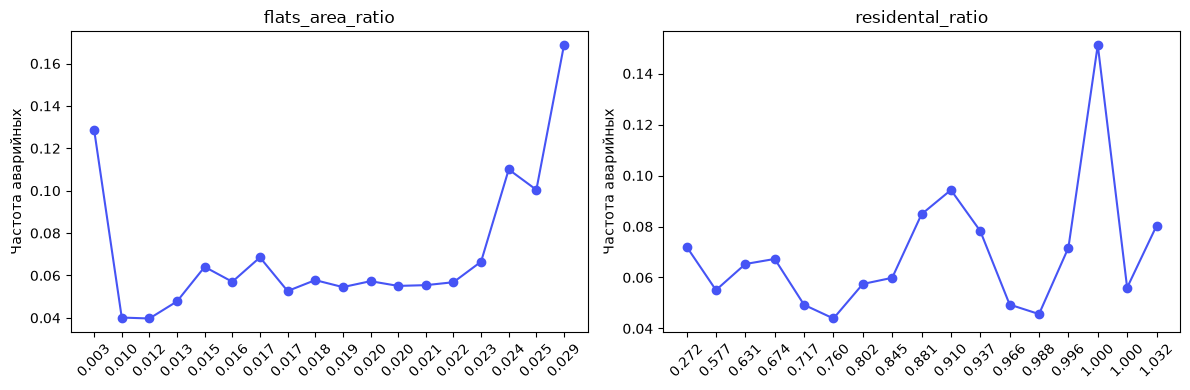

In [310]:
quantiles = np.linspace(0, 1, 20, endpoint=False)

fig, axes = plt.subplots(1, 2, figsize=(12,4))
for ax, col in zip(axes.flat, ["flats_area_ratio", "residental_ratio"]):
    bins = pd.qcut(df[col], q=quantiles, duplicates="drop")
    temp = df.groupby(bins)[TARGET].mean()
    ax.plot(
        temp.values,
        marker='o',
        color=PLOT_COLOR
    )
    # ax.set_ylim(0,1)
    ax.set_xticks(ticks=range(len(temp)), labels=[f"{b.mid:.3f}" for b in temp.index], rotation=45)
    ax.set_title(col, color=COLORS["text"])
    ax.set_ylabel("Частота аварийных")

plt.tight_layout()
plt.show()

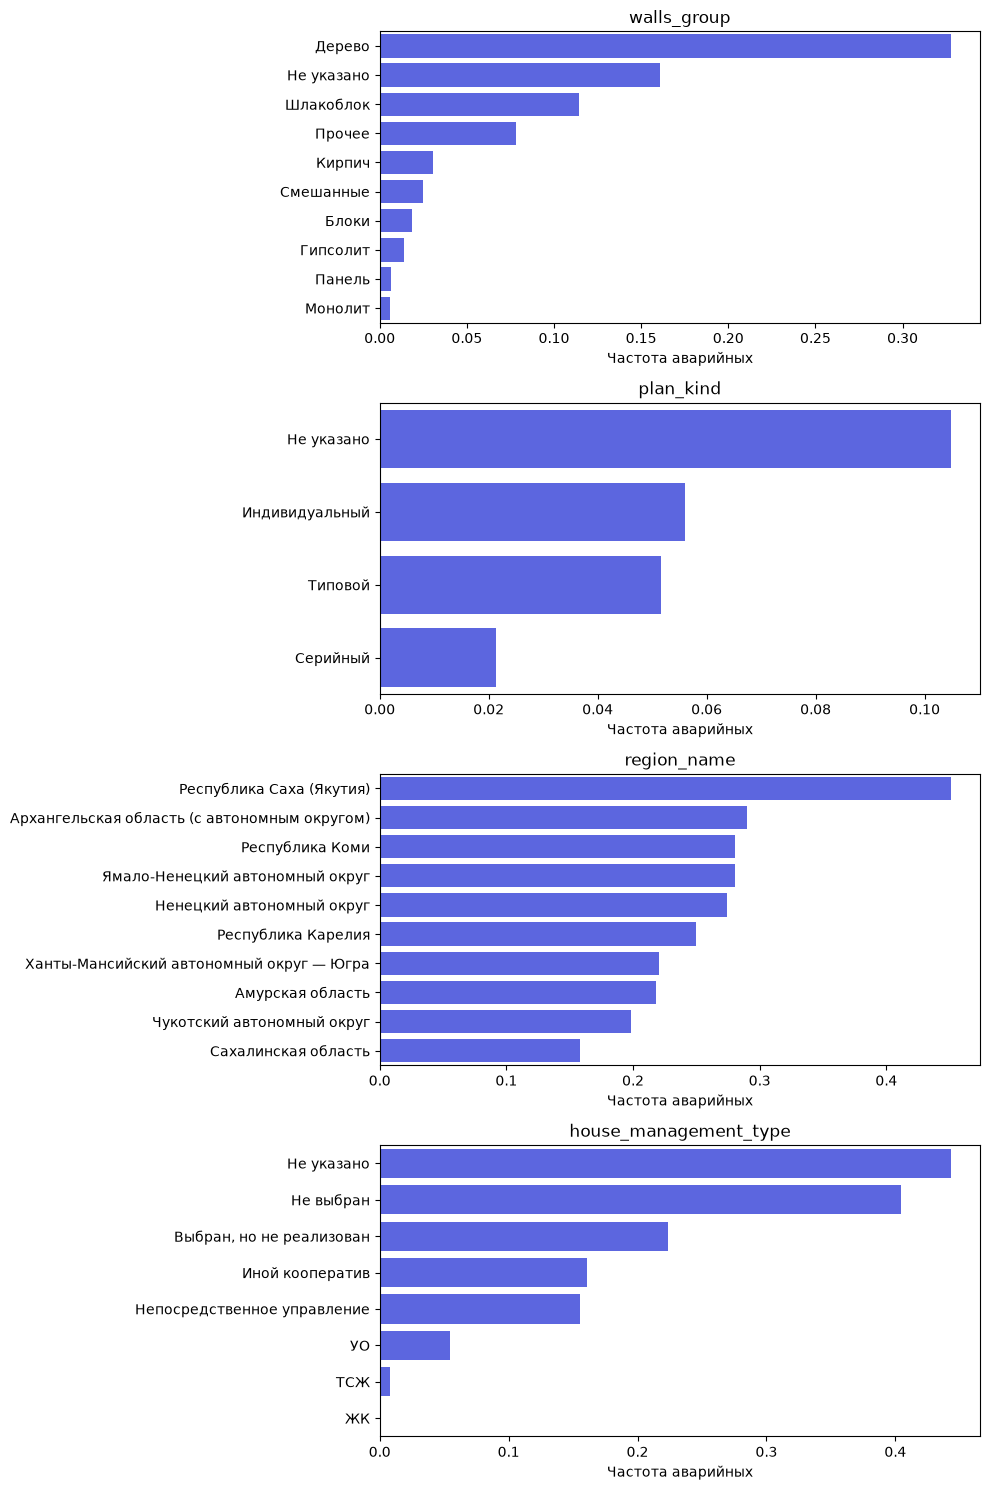

In [311]:
fig, axes = plt.subplots(4, 1, figsize=(10,15))
for ax, col in zip(axes.flat, ["walls_group", "plan_kind", "region_name", "house_management_type"]):
    temp = df.groupby(col)[TARGET].mean().sort_values(ascending=False).head(10)
    sns.barplot(
        x=temp.values,
        y=temp.index,
        ax=ax,
        color=PLOT_COLOR
    )
    ax.set_ylabel("")
    ax.set_xlabel("Частота аварийных")
    ax.set_title(col, color=COLORS["text"])

plt.tight_layout()
plt.show()

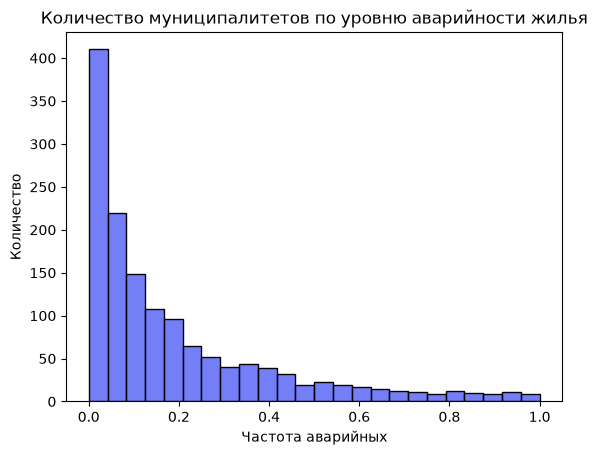

In [312]:
# Распределение муниципалитетов по аварийности

temp = df.groupby("municipality_oktmo")[TARGET].mean().reset_index().groupby(TARGET).count()
sns.histplot(
    x=temp.index,
    color=PLOT_COLOR
)
plt.title("Количество муниципалитетов по уровню аварийности жилья")
plt.xlabel("Частота аварийных")
plt.ylabel("Количество")
plt.show()

In [313]:
temp = pd.DataFrame(
    index=[
        "Corr",
        "Buiding year == Comissioning year",
        "Buiding year < Comissioning year",
        "Buiding year > Comissioning year",
    ],
    data=[
        df[["building_year", "comissioning_year"]].corr("spearman").iloc[0,1],
        (df["building_year"] == df["comissioning_year"]).sum(),
        (df["building_year"] < df["comissioning_year"]).sum(),
        (df["building_year"] > df["comissioning_year"]).sum(),
    ],
    columns=["Count"]
)
style_table(temp, "", hide_index=False).format({"Count": "{:,.2f}"})

,Count
Corr,0.96
Buiding year == Comissioning year,"741,966.00"
Buiding year < Comissioning year,"49,010.00"
Buiding year > Comissioning year,"26,014.00"


## Дизайн статистического исследования
В качестве базовой модели выбран алгоритм градиентного бустинга над деревьями решений — **CatBoost** (Categorical Boosting).

Его преимущества для данного исследования:
1. **Нативная обработка категорий**: CatBoost математически корректно работает со строковыми (текстовыми) признаками "под капотом", используя целевое кодирование (Target Encoding). Это позволяет модели находить сложные нелинейные связи между субъектом РФ, серией здания и его износом.
2. **Устойчивость к выбросам и неполным данным**: Древовидная архитектура бустинга робастна к нетипичным значениям (например, ошибкам ввода площади), которые неизбежно присутствуют в массивах государственной статистики.
3. **Встроенная компенсация дисбаланса**: Использование гиперпараметра auto_class_weights='Balanced' заставляет функцию потерь штрафовать модель пропорционально редкости аварийного класса, максимизируя способность алгоритма "отлавливать" проблемные объекты.

In [42]:
category_features = [
    "walls_group", 
    "plan_kind", 
    "region_name", 
    "municipality_oktmo", 
    "house_management_type",
]

continues_features = [
    "building_year", 
    "total_area", 
    "residental_premises_area", 
    "flats"
]

ratio_features = [
    "flats_area_ratio",
    "residental_ratio"
]

boolean_features = [
    "is_reconstructed",
    "municipal_property"
]

In [46]:
from catboost import CatBoostClassifier, Pool
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

feautures = category_features + continues_features + ratio_features + boolean_features
X = df[feautures]
y = df[TARGET]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cb_params = dict(
    iterations=3000,
    depth = 8,
    learning_rate=0.1,
    early_stopping_rounds=100,
    random_seed=42,
    thread_count = -1,
    verbose=0
)

oof = np.zeros(len(X))
for i, (tr, va) in enumerate(cv.split(X,y)):
    tr_pool = Pool(X.iloc[tr], y.iloc[tr], cat_features=category_features)
    va_pool = Pool(X.iloc[va], y.iloc[va], cat_features=category_features)

    model = CatBoostClassifier(**cb_params)
    model.fit(tr_pool, eval_set=va_pool, use_best_model=True)

    oof[va] = model.predict_proba(va_pool)[:,1]
    print(f"fold {i}: AUC = {roc_auc_score(y.iloc[va], oof[va]):.5f}, best_iter = {model.get_best_iteration()}")

fold 0: AUC = 0.96996, best_iter = 2235
fold 1: AUC = 0.97145, best_iter = 2648
fold 2: AUC = 0.97220, best_iter = 2761
fold 3: AUC = 0.97072, best_iter = 2349
fold 4: AUC = 0.97036, best_iter = 2579


## Метрики оценки качества
Учитывая дисбаланс классов, стандартная метрика **Accuracy** (доля правильных ответов) является нерепрезентативной. Оценка качества алгоритма будет производиться на основе метрик **Precision** (точность), **Recall** (полнота), а также метрики **F1-score** и матрицы ошибок (**Confusion Matrix**). Для интерпретации социологических результатов будет применен анализ важности признаков (**Feature Importances**).

In [53]:
from sklearn.metrics import classification_report

preds = oof > 0.5
print(classification_report(y, preds))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98    751589
           1       0.80      0.63      0.71     65401

    accuracy                           0.96    816990
   macro avg       0.88      0.81      0.84    816990
weighted avg       0.96      0.96      0.96    816990



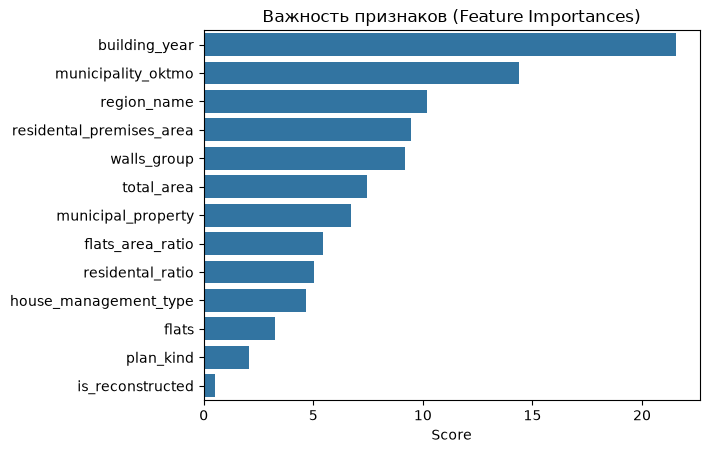

In [71]:
feature_importances = model.get_feature_importance()
feature_importances_df = pd.DataFrame(data=feature_importances, index=X.columns, columns=["Score"])
feature_importances_df = feature_importances_df.sort_values("Score", ascending=False)

sns.barplot(data=feature_importances_df, y=feature_importances_df.index, x="Score")
plt.title("Важность признаков (Feature Importances)")
plt.ylabel("")
plt.show()

### Вывод по Feature Importances:
1. Физические признаки
- Абсолютным лидером по силе предсказания ожидаемо стал **building_year** (Год постройки). Это подтверждает адекватность модели: законы физики и естественный износ материалов выступают первичным фактором риска. В связке с ним работают структурные характеристики: **total_area** (Общая площадь) и **walls_group** (Материал стен). Высокая значимость площади объясняется тем, что основу аварийного фонда исторически составляют малоэтажные дома небольшой площади (например, двухэтажные деревянные бараки), в то время как крупные массивы поздней советской застройки деградируют медленнее.
2. Социально-пространственное неравенство
- Наибольший интерес представляет то, что пространственно-географические признаки — **municipality_oktmo** (Муниципалитет) и **region_name** (Регион) — заняли 2-е и 3-е места среди всех факторов (не считая площади), в совокупности формируя колоссальный вес в принятии решения моделью.
Это доказывает выдвинутую гипотезу: статус «аварийного дома» — это социально-бюрократический конструкт. При одинаковом возрасте, площади и материале стен вероятность признания дома аварийным кардинально различается в зависимости от субъекта РФ и конкретного города. Это прямое отражение бюджетной обеспеченности: богатые муниципалитеты имеют средства на расселение и быстрее "навешивают" статус аварийности на старый фонд, тогда как в депрессивных регионах процесс бюрократически тормозится.
3. Роль институтов управления
- Институциональный признак **house_manegement_type** (Способ управления) вошел в ядро значимых факторов. Хотя его глобальный вес уступает возрасту и географии, его влияние остается статистически существенным. Алгоритм учитывает юридическую форму управления (например, защитный эффект ТСЖ по сравнению с муниципальными УК) при оценке риска деградации, что подтверждает важность прав коллективной собственности.
4. Специфика бинарных признаков
- Сконструированные бинарные признаки **is_reconstructed** (Факт реконструкции) и **is_dormitory** (Статус общежития) показали низкую глобальную важность. С методологической точки зрения машинного обучения это легко объяснимо: доля общежитий и реконструированных домов в генеральной совокупности (950 тыс. зданий) ничтожно мала. Алгоритм редко использует эти признаки для разбиения всей выборки. Однако их низкая глобальная важность не отменяет их высокой локальной значимости: для конкретного здания сам факт наличия статуса "общежитие" может выступать критическим триггером разрушения, что требует дальнейшего изучения

## Вывод
Таким образом, первоначальная исследовательская гипотеза подтвердилась: статус аварийности дома не является случайной, а алгоритмически выводим из набора объективных характеристик здания и институциональной среды.